# NGLD 葡萄叶片病害分类训练 | ResNet50 + CBAM

## 1. 导入库与训练配置

In [1]:
DATASET_NAME = "Niphad Grape Leaf Disease Dataset (NGLD)"

import json
import os
import random
import time
import warnings
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import torch
import torch.nn as nn
import torch.nn.functional as F
import torchvision
from IPython.display import Image as IPyImage
from IPython.display import display
from PIL import Image, ImageFile
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    precision_recall_fscore_support,
    roc_auc_score,
)
from torch.utils.data import DataLoader, Dataset
from torchvision import models, transforms
from tqdm import tqdm

warnings.filterwarnings("ignore")
ImageFile.LOAD_TRUNCATED_IMAGES = True
plt.rcParams["font.sans-serif"] = ["SimHei", "DejaVu Sans", "Arial Unicode MS", "Microsoft YaHei"]
plt.rcParams["axes.unicode_minus"] = False
plt.rcParams["axes.formatter.use_mathtext"] = False

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)
if torch.cuda.is_available():
    torch.cuda.manual_seed_all(SEED)

DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")
BATCH_SIZE = 32
NUM_EPOCHS = 100
IMG_SIZE = 224
NUM_WORKERS = 0

USE_PRETRAINED = True
PHASE1_EPOCHS = 10
PHASE1_LR = 1e-3
PHASE2_LR = 1e-4
WEIGHT_DECAY = 0.0
PATIENCE = 10
SCHEDULER_FACTOR = 0.1
SCHEDULER_PATIENCE = 2

HIDDEN_DIM = 512
DROPOUT = 0.5
UNFREEZE_SCOPE = "layer3_layer4"   # "layer3_layer4" 或 "all"

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name.lower() == "train":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / DATASET_NAME
MODEL_DIR = PROJECT_ROOT / "models"
RUNS_DIR = PROJECT_ROOT / "train" / "runs"
OUTPUT_ROOT = RUNS_DIR / "ngld_resnet50_cbam"
CHECKPOINT_PATH = OUTPUT_ROOT / "best_model.pth"
FINAL_MODEL_PATH = MODEL_DIR / "ngld_resnet50_cbam.pth"

MODEL_DIR.mkdir(parents=True, exist_ok=True)
OUTPUT_ROOT.mkdir(parents=True, exist_ok=True)

if not DATA_DIR.is_dir():
    raise FileNotFoundError(f"Dataset directory not found: {DATA_DIR}")

print(f"Dataset: {DATA_DIR.resolve()}")
print(f"Model output: {MODEL_DIR.resolve()}")
print(f"Run output: {OUTPUT_ROOT.resolve()}")
print(f"Device: {DEVICE}")
print(f"预训练权重: {'ImageNet' if USE_PRETRAINED else '随机初始化（从零训练）'}")
print(f"训练策略: 阶段1 {PHASE1_EPOCHS} 轮（冻结 backbone）→ 阶段2 解冻 {UNFREEZE_SCOPE}")
print(f"学习率: 阶段1 {PHASE1_LR}, 阶段2 {PHASE2_LR}")
print(f"最大训练轮数: {NUM_EPOCHS} | 早停耐心: {PATIENCE}")

Dataset: D:\WorkSpace2\plants-intelligent-system\Niphad Grape Leaf Disease Dataset (NGLD)
Model output: D:\WorkSpace2\plants-intelligent-system\models
Run output: D:\WorkSpace2\plants-intelligent-system\train\runs\ngld_resnet50_cbam
Device: cuda
预训练权重: ImageNet
训练策略: 阶段1 10 轮（冻结 backbone）→ 阶段2 解冻 layer3_layer4
学习率: 阶段1 0.001, 阶段2 0.0001
最大训练轮数: 100 | 早停耐心: 10


## 2. 数据加载与数据增强

## 2.1 数据集初始化

In [2]:
IMAGE_EXTS = {".jpg", ".jpeg", ".png", ".bmp", ".webp", ".tif", ".tiff"}
SKIP_DIR_NAMES = {
    "train", "training", "val", "valid", "validation",
    "test", "testing", "color", "grayscale", "segmented", "images",
}


def collect_samples(root):
    root = Path(root)
    rows = []
    for path in root.rglob("*"):
        if not path.is_file() or path.suffix.lower() not in IMAGE_EXTS:
            continue
        parts = [p for p in path.relative_to(root).parts[:-1] if p.lower() not in SKIP_DIR_NAMES]
        if not parts:
            continue
        rows.append({"path": str(path.resolve()), "class_name": parts[-1]})

    df = pd.DataFrame(rows).drop_duplicates(subset=["path"]).reset_index(drop=True)
    if df.empty:
        raise RuntimeError(f"在 {root} 下没有找到图片")
    return df


df = collect_samples(DATA_DIR)
class_names = sorted(df["class_name"].unique())
class_to_idx = {name: i for i, name in enumerate(class_names)}
num_classes = len(class_names)


def stratified_split_exact(df, class_names, seed=SEED):
    train_parts, val_parts, test_parts = [], [], []
    for class_name in class_names:
        subset = df[df["class_name"] == class_name].sample(frac=1.0, random_state=seed).reset_index(drop=True)
        n = len(subset)
        n_train = int(round(n * 0.8))
        n_val = int(round(n * 0.1))
        train_parts.append(subset.iloc[:n_train])
        val_parts.append(subset.iloc[n_train:n_train + n_val])
        test_parts.append(subset.iloc[n_train + n_val:])

    def combine(parts):
        return pd.concat(parts, ignore_index=True).sample(frac=1.0, random_state=seed).reset_index(drop=True)

    return combine(train_parts), combine(val_parts), combine(test_parts)


train_df, val_df, test_df = stratified_split_exact(df, class_names, seed=SEED)
for frame, split in ((train_df, "train"), (val_df, "val"), (test_df, "test")):
    frame["split"] = split

split_df = pd.concat([train_df, val_df, test_df], ignore_index=True)
split_df["relative_path"] = split_df["path"].map(
    lambda p: os.path.relpath(p, PROJECT_ROOT) if os.path.exists(p) else p
)
split_path = OUTPUT_ROOT / f"split_seed{SEED}.csv"
split_df[["relative_path", "class_name", "split"]].to_csv(split_path, index=False)

IMAGENET_MEAN = [0.485, 0.456, 0.406]
IMAGENET_STD = [0.229, 0.224, 0.225]

train_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.RandomHorizontalFlip(p=0.5),
    transforms.RandomRotation(degrees=72),
    transforms.RandomAffine(
        degrees=0,
        translate=(0.1, 0.1),
        scale=(0.8, 1.2),
        interpolation=transforms.InterpolationMode.BILINEAR,
        fill=0,
    ),
    transforms.ColorJitter(contrast=0.2),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])

eval_transform = transforms.Compose([
    transforms.Resize((IMG_SIZE, IMG_SIZE)),
    transforms.ToTensor(),
    transforms.Normalize(IMAGENET_MEAN, IMAGENET_STD),
])


class GrapeDataset(Dataset):
    def __init__(self, frame, transform):
        self.paths = frame["path"].tolist()
        self.labels = [class_to_idx[name] for name in frame["class_name"].tolist()]
        self.transform = transform

    def __len__(self):
        return len(self.paths)

    def __getitem__(self, index):
        image = Image.open(self.paths[index]).convert("RGB")
        return self.transform(image), self.labels[index]


def make_loaders(seed):
    generator = torch.Generator()
    generator.manual_seed(seed)
    common = dict(num_workers=NUM_WORKERS, pin_memory=(DEVICE.type == "cuda"))
    train_loader = DataLoader(
        GrapeDataset(train_df, train_transform),
        batch_size=BATCH_SIZE,
        shuffle=True,
        generator=generator,
        **common,
    )
    val_loader = DataLoader(
        GrapeDataset(val_df, eval_transform),
        batch_size=BATCH_SIZE,
        shuffle=False,
        **common,
    )
    test_loader = DataLoader(
        GrapeDataset(test_df, eval_transform),
        batch_size=BATCH_SIZE,
        shuffle=False,
        **common,
    )
    return train_loader, val_loader, test_loader


train_loader, val_loader, test_loader = make_loaders(SEED)

print("Classes:", class_to_idx)
print(f"train: {len(train_df)} images")
print(f"val:   {len(val_df)} images")
print(f"test:  {len(test_df)} images")
print("split 已保存:", split_path)
print("数据增强:")
print("  - RandomHorizontalFlip")
print("  - RandomRotation(±72°)")
print("  - RandomAffine(scale=0.8-1.2, translate=±10%)")
print("  - ColorJitter(contrast=0.2)")

Classes: {'Bacterial Rot': 0, 'Downey Mildew': 1, 'Healthy Leaves': 2, 'Powdery Mildew': 3}
train: 2181 images
val:   273 images
test:  272 images
split 已保存: D:\WorkSpace2\plants-intelligent-system\train\runs\ngld_resnet50_cbam\split_seed42.csv
数据增强:
  - RandomHorizontalFlip
  - RandomRotation(±72°)
  - RandomAffine(scale=0.8-1.2, translate=±10%)
  - ColorJitter(contrast=0.2)


## 2.2 数据集统计

class_name,Bacterial Rot,Downey Mildew,Healthy Leaves,Powdery Mildew
split,,,,
train,80,773,1003,325
val,10,97,125,41
test,10,96,126,40


训练集最大/最小类别样本数: 1003 / 80 = 12.54:1


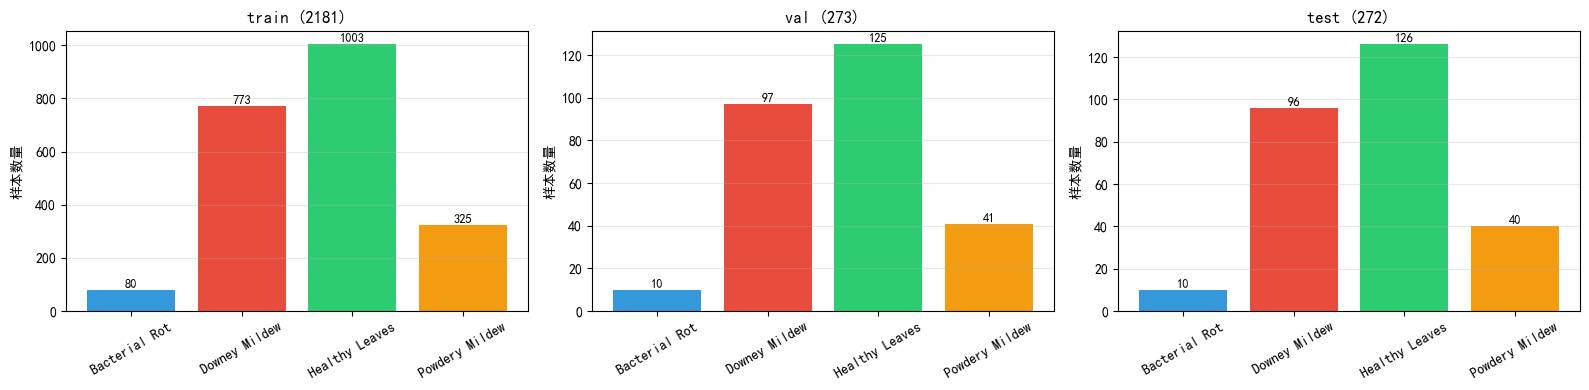

In [3]:
split_order = ["train", "val", "test"]
counts_by_split = (
    split_df.groupby(["split", "class_name"]).size().unstack(fill_value=0)
    .reindex(index=split_order, columns=class_names)
)
display(counts_by_split)

train_counts = counts_by_split.loc["train"]
imbalance_ratio = train_counts.max() / max(1, train_counts.min())
print(
    f"训练集最大/最小类别样本数: {int(train_counts.max())} / {int(train_counts.min())} "
    f"= {imbalance_ratio:.2f}:1"
)

colors = ["#3498db", "#e74c3c", "#2ecc71", "#f39c12", "#9b59b6", "#1abc9c"]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, split in zip(axes, split_order):
    values = counts_by_split.loc[split]
    bars = ax.bar(class_names, values, color=[colors[i % len(colors)] for i in range(len(class_names))])
    ax.set_title(f"{split} ({int(values.sum())})")
    ax.set_ylabel("样本数量")
    ax.tick_params(axis="x", rotation=30)
    ax.grid(axis="y", alpha=0.3)
    for bar, value in zip(bars, values):
        ax.text(
            bar.get_x() + bar.get_width() / 2,
            bar.get_height(),
            str(int(value)),
            ha="center",
            va="bottom",
            fontsize=9,
        )
plt.tight_layout()
plt.savefig(OUTPUT_ROOT / "dataset_distribution.png", dpi=150, bbox_inches="tight")
plt.show()

## 3. 训练样本展示

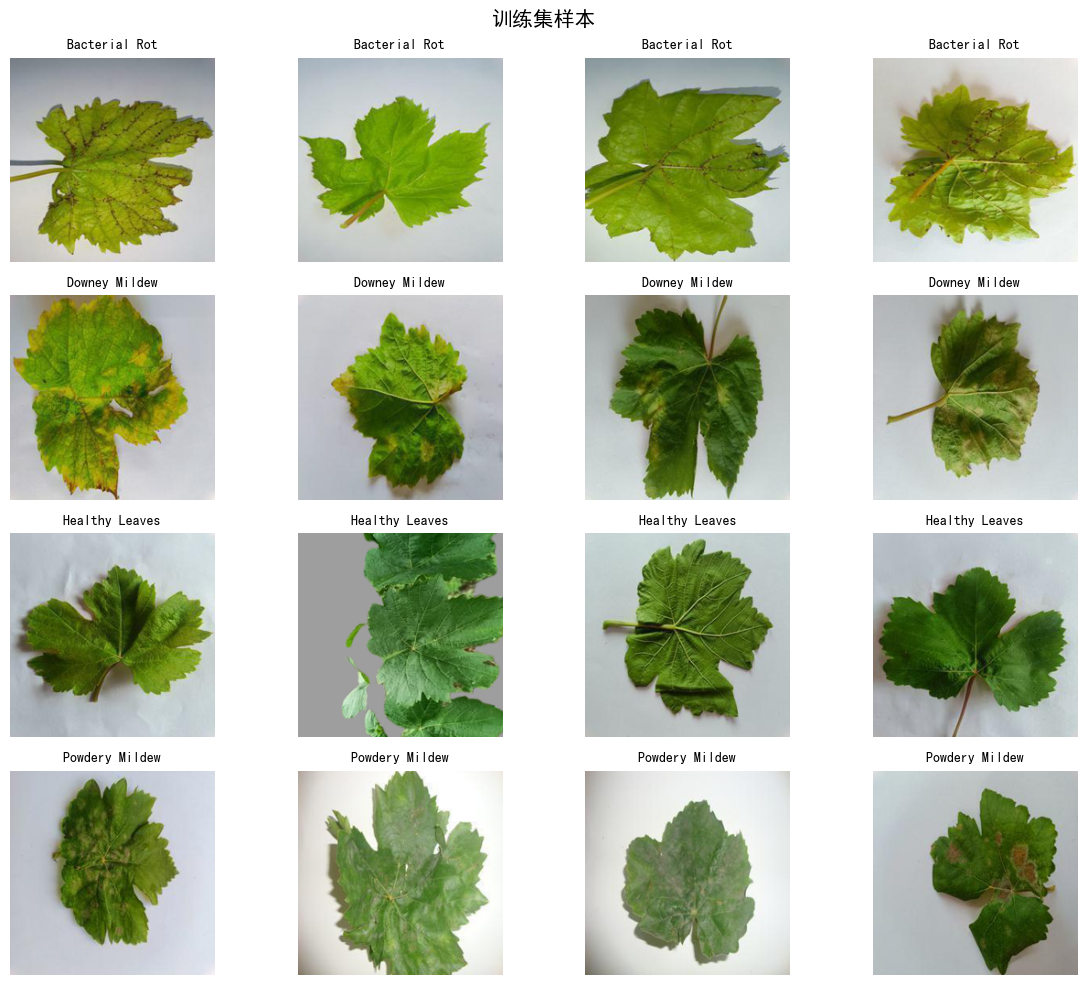

In [4]:
from PIL import ImageOps

samples = (
    train_df.groupby("class_name", group_keys=False)
    .apply(lambda x: x.sample(n=min(4, len(x)), random_state=SEED))
    .reset_index(drop=True)
)

n_samples = len(samples)
n_cols = 4
n_rows = max(1, (n_samples + n_cols - 1) // n_cols)
fig, axes = plt.subplots(n_rows, n_cols, figsize=(3 * n_cols, 2.5 * n_rows))
axes = np.atleast_1d(axes).flatten()

for ax, (_, row) in zip(axes, samples.iterrows()):
    image = ImageOps.fit(Image.open(row["path"]).convert("RGB"), (IMG_SIZE, IMG_SIZE))
    ax.imshow(image)
    ax.set_title(row["class_name"], fontsize=10)
    ax.axis("off")
for ax in axes[n_samples:]:
    ax.axis("off")

fig.suptitle("训练集样本", fontsize=15)
plt.tight_layout()
plt.savefig(OUTPUT_ROOT / "train_samples.png", dpi=130, bbox_inches="tight")
plt.show()

## 4. ResNet50 + CBAM 模型

In [5]:
class ChannelAttention(nn.Module):
    def __init__(self, in_channels, reduction=16):
        super().__init__()
        self.avg_pool = nn.AdaptiveAvgPool2d(1)
        self.max_pool = nn.AdaptiveMaxPool2d(1)
        self.fc = nn.Sequential(
            nn.Conv2d(in_channels, in_channels // reduction, 1, bias=False),
            nn.ReLU(inplace=True),
            nn.Conv2d(in_channels // reduction, in_channels, 1, bias=False),
        )
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        return self.sigmoid(self.fc(self.avg_pool(x)) + self.fc(self.max_pool(x)))


class SpatialAttention(nn.Module):
    def __init__(self, kernel_size=7):
        super().__init__()
        self.conv = nn.Conv2d(2, 1, kernel_size, padding=kernel_size // 2, bias=False)
        self.sigmoid = nn.Sigmoid()

    def forward(self, x):
        avg_out = torch.mean(x, dim=1, keepdim=True)
        max_out, _ = torch.max(x, dim=1, keepdim=True)
        return self.sigmoid(self.conv(torch.cat([avg_out, max_out], dim=1)))


class CBAM(nn.Module):
    def __init__(self, in_channels, reduction=16):
        super().__init__()
        self.ca = ChannelAttention(in_channels, reduction)
        self.sa = SpatialAttention()

    def forward(self, x):
        x = x * self.ca(x)
        return x * self.sa(x)


class ResNet50CBAM(nn.Module):
    def __init__(self, num_classes, pretrained=True, hidden_dim=HIDDEN_DIM, dropout=DROPOUT):
        super().__init__()
        weights = models.ResNet50_Weights.IMAGENET1K_V1 if pretrained else None
        try:
            backbone = models.resnet50(weights=weights)
        except Exception as exc:
            print("预训练权重加载失败，改为随机初始化:", exc)
            backbone = models.resnet50(weights=None)

        self.backbone = backbone
        self.backbone.fc = nn.Identity()
        self.cbam = CBAM(2048)
        self.pool = nn.AdaptiveAvgPool2d(1)
        self.head = nn.Sequential(
            nn.Linear(2048, hidden_dim),
            nn.ReLU(inplace=True),
            nn.Dropout(dropout),
            nn.Linear(hidden_dim, num_classes),
        )

    def forward(self, x):
        b = self.backbone
        x = b.conv1(x)
        x = b.bn1(x)
        x = b.relu(x)
        x = b.maxpool(x)
        x = b.layer1(x)
        x = b.layer2(x)
        x = b.layer3(x)
        x = b.layer4(x)
        x = self.cbam(x)
        x = self.pool(x)
        x = torch.flatten(x, 1)
        return self.head(x)


model = ResNet50CBAM(num_classes, pretrained=USE_PRETRAINED).to(DEVICE)
print(f"种类数量: {num_classes}")
print(f"总参数量: {sum(p.numel() for p in model.parameters()):,}")
print(f"可训练参数量: {sum(p.numel() for p in model.parameters() if p.requires_grad):,}")

种类数量: 4
总参数量: 25,083,558
可训练参数量: 25,083,558


## 5. 训练循环（早停与模型保存）

In [6]:
def configure_trainable(model, phase):
    for name, param in model.backbone.named_parameters():
        if phase == 1:
            param.requires_grad = False
        elif UNFREEZE_SCOPE == "all":
            param.requires_grad = True
        else:
            param.requires_grad = name.startswith(("layer3", "layer4"))
    for module in (model.cbam, model.head):
        for param in module.parameters():
            param.requires_grad = True


def set_train_mode(model, phase):
    model.train()
    if phase == 1:
        for module in model.backbone.modules():
            if isinstance(module, nn.BatchNorm2d):
                module.eval()
    elif UNFREEZE_SCOPE != "all":
        for name, module in model.backbone.named_modules():
            if isinstance(module, nn.BatchNorm2d) and not name.startswith(("layer3", "layer4")):
                module.eval()


def make_optimizer(model, lr):
    params = [p for p in model.parameters() if p.requires_grad]
    return torch.optim.Adam(params, lr=lr, weight_decay=WEIGHT_DECAY)


def make_scheduler(optimizer):
    return torch.optim.lr_scheduler.ReduceLROnPlateau(
        optimizer,
        mode="min",
        factor=SCHEDULER_FACTOR,
        patience=SCHEDULER_PATIENCE,
        min_lr=1e-6,
    )


train_counts = train_df["class_name"].value_counts().reindex(class_names)
class_weights = len(train_df) / (num_classes * train_counts)
class_weights_tensor = torch.tensor(class_weights.values, dtype=torch.float32, device=DEVICE)
criterion = nn.CrossEntropyLoss(weight=class_weights_tensor)

# 类别权重：按 N/(K*count) 计算，缓解类别不平衡

USE_AMP = DEVICE.type == "cuda"


def train_epoch(model, loader, criterion, optimizer, scaler, phase, epoch):
    set_train_mode(model, phase)
    running_loss = 0.0
    correct = 0
    total = 0

    for images, labels in tqdm(loader, desc='训练', leave=False, dynamic_ncols=True):
        images = images.to(DEVICE, non_blocking=True)
        labels = labels.to(DEVICE, non_blocking=True)
        optimizer.zero_grad(set_to_none=True)

        with torch.cuda.amp.autocast(enabled=USE_AMP):
            logits = model(images)
            loss = criterion(logits, labels)

        if USE_AMP:
            scaler.scale(loss).backward()
            scaler.step(optimizer)
            scaler.update()
        else:
            loss.backward()
            optimizer.step()

        running_loss += loss.item() * labels.size(0)
        correct += (logits.argmax(1) == labels).sum().item()
        total += labels.size(0)

    return running_loss / total, correct / total


def evaluate(model, loader, criterion):
    model.eval()
    running_loss = 0.0
    total = 0
    y_true, y_pred, y_prob = [], [], []

    with torch.no_grad():
        for images, labels in tqdm(loader, desc='验证', leave=False, dynamic_ncols=True):
            images = images.to(DEVICE, non_blocking=True)
            labels = labels.to(DEVICE, non_blocking=True)
            logits = model(images)
            loss = criterion(logits, labels)
            probs = F.softmax(logits, dim=1)

            running_loss += loss.item() * labels.size(0)
            total += labels.size(0)
            y_true.extend(labels.cpu().tolist())
            y_pred.extend(logits.argmax(1).cpu().tolist())
            y_prob.extend(probs.cpu().tolist())

    return running_loss / total, float(np.mean(np.asarray(y_true) == np.asarray(y_pred))), y_true, y_pred, np.asarray(y_prob)

In [7]:
def run_training():
    random.seed(SEED)
    np.random.seed(SEED)
    torch.manual_seed(SEED)
    if torch.cuda.is_available():
        torch.cuda.manual_seed_all(SEED)

    model = ResNet50CBAM(num_classes, pretrained=USE_PRETRAINED).to(DEVICE)
    configure_trainable(model, phase=1)

    optimizer = make_optimizer(model, PHASE1_LR)
    scheduler = make_scheduler(optimizer)
    scaler = torch.cuda.amp.GradScaler(enabled=USE_AMP)

    best_val_loss = float("inf")
    best_val_acc = 0.0
    best_epoch = 0
    best_phase = 1
    best_state = None
    bad_epochs = 0
    history = []
    phase = 1

    print("阶段 1：冻结整个 backbone，只训练 CBAM + head")
    started = time.time()

    for epoch in range(1, NUM_EPOCHS + 1):
        if epoch == PHASE1_EPOCHS + 1:
            phase = 2
            configure_trainable(model, phase=2)
            optimizer = make_optimizer(model, PHASE2_LR)
            scheduler = make_scheduler(optimizer)
            bad_epochs = 0
            print(f"阶段 2：解冻 {UNFREEZE_SCOPE}，学习率 {PHASE2_LR}")

        train_loss, train_acc = train_epoch(model, train_loader, criterion, optimizer, scaler, phase, epoch)
        val_loss, val_acc, _, _, _ = evaluate(model, val_loader, criterion)
        scheduler.step(val_loss)
        current_lr = optimizer.param_groups[0]["lr"]

        history.append({
            "epoch": epoch,
            "phase": phase,
            "train_loss": train_loss,
            "train_acc": train_acc,
            "val_loss": val_loss,
            "val_acc": val_acc,
            "lr": current_lr,
        })
        pd.DataFrame(history).to_csv(OUTPUT_ROOT / "training_history.csv", index=False)

        improved = val_loss < best_val_loss - 1e-6
        if improved:
            best_val_loss = val_loss
            best_val_acc = val_acc
            best_epoch = epoch
            best_phase = phase
            best_state = {k: v.detach().cpu().clone() for k, v in model.state_dict().items()}
            bad_epochs = 0
        else:
            bad_epochs += 1

        print(
            f"epoch {epoch:03d}/{NUM_EPOCHS} | phase {phase} | lr {current_lr:.2e} | "
            f"train loss {train_loss:.4f} acc {train_acc:.4f} | "
            f"val loss {val_loss:.4f} acc {val_acc:.4f} | "
            f"best {best_val_loss:.4f}@{best_epoch}"
        )

        if phase == 2 and bad_epochs >= PATIENCE:
            print(f"EarlyStopping: 验证 loss 连续 {PATIENCE} 轮未改善，停止。")
            break

    elapsed = time.time() - started
    model.load_state_dict(best_state)

    checkpoint = {
        "epoch": best_epoch,
        "phase": best_phase,
        "model_state_dict": best_state,
        "val_loss": best_val_loss,
        "val_acc": best_val_acc,
        "class_names": class_names,
        "config": {
            "img_size": IMG_SIZE,
            "batch_size": BATCH_SIZE,
            "hidden_dim": HIDDEN_DIM,
            "dropout": DROPOUT,
            "unfreeze_scope": UNFREEZE_SCOPE,
            "phase1_epochs": PHASE1_EPOCHS,
            "phase1_lr": PHASE1_LR,
            "phase2_lr": PHASE2_LR,
            "pretrained": USE_PRETRAINED,
        },
    }
    torch.save(checkpoint, CHECKPOINT_PATH)
    torch.save(model.state_dict(), FINAL_MODEL_PATH)
    pd.DataFrame(history).to_csv(OUTPUT_ROOT / "training_history.csv", index=False)

    print("训练完成")
    print(f"最佳 epoch: {best_epoch} (phase {best_phase})")
    print(f"最佳验证损失: {best_val_loss:.4f} | 最佳验证准确率: {best_val_acc:.4f}")
    print(f"耗时: {elapsed / 60:.1f} 分钟")
    print(f"最佳模型: {CHECKPOINT_PATH}")
    print(f"最终模型: {FINAL_MODEL_PATH}")
    return model, history


model, history = run_training()

阶段 1：冻结整个 backbone，只训练 CBAM + head


epoch 001/100 | phase 1 | lr 1.00e-03 | train loss 1.0358 acc 0.6396 | val loss 0.7021 acc 0.8242 | best 0.7021@1


epoch 002/100 | phase 1 | lr 1.00e-03 | train loss 0.5860 acc 0.8006 | val loss 0.4479 acc 0.8791 | best 0.4479@2


epoch 003/100 | phase 1 | lr 1.00e-03 | train loss 0.4660 acc 0.8436 | val loss 0.5334 acc 0.8755 | best 0.4479@2


epoch 004/100 | phase 1 | lr 1.00e-03 | train loss 0.4162 acc 0.8583 | val loss 0.3334 acc 0.9048 | best 0.3334@4


epoch 005/100 | phase 1 | lr 1.00e-03 | train loss 0.4249 acc 0.8510 | val loss 0.4071 acc 0.8974 | best 0.3334@4


... (15 outputs left out)

epoch 021/100 | phase 2 | lr 1.00e-06 | train loss 0.0197 acc 0.9922 | val loss 0.0478 acc 0.9890 | best 0.0277@14


epoch 022/100 | phase 2 | lr 1.00e-06 | train loss 0.0181 acc 0.9936 | val loss 0.0553 acc 0.9890 | best 0.0277@14


epoch 023/100 | phase 2 | lr 1.00e-06 | train loss 0.0110 acc 0.9954 | val loss 0.0493 acc 0.9890 | best 0.0277@14


epoch 024/100 | phase 2 | lr 1.00e-06 | train loss 0.0112 acc 0.9968 | val loss 0.0457 acc 0.9890 | best 0.0277@14
EarlyStopping: 验证 loss 连续 10 轮未改善，停止。
训练完成
最佳 epoch: 14 (phase 2)
最佳验证损失: 0.0277 | 最佳验证准确率: 0.9927
耗时: 8.0 分钟
最佳模型: D:\WorkSpace2\plants-intelligent-system\train\runs\ngld_resnet50_cbam\best_model.pth
最终模型: D:\WorkSpace2\plants-intelligent-system\models\ngld_resnet50_cbam.pth


## 6. 训练历史可视化

Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], substituting with a dummy symbol.
Font 'default' does not have a glyph for '\u2212' [U+2212], 

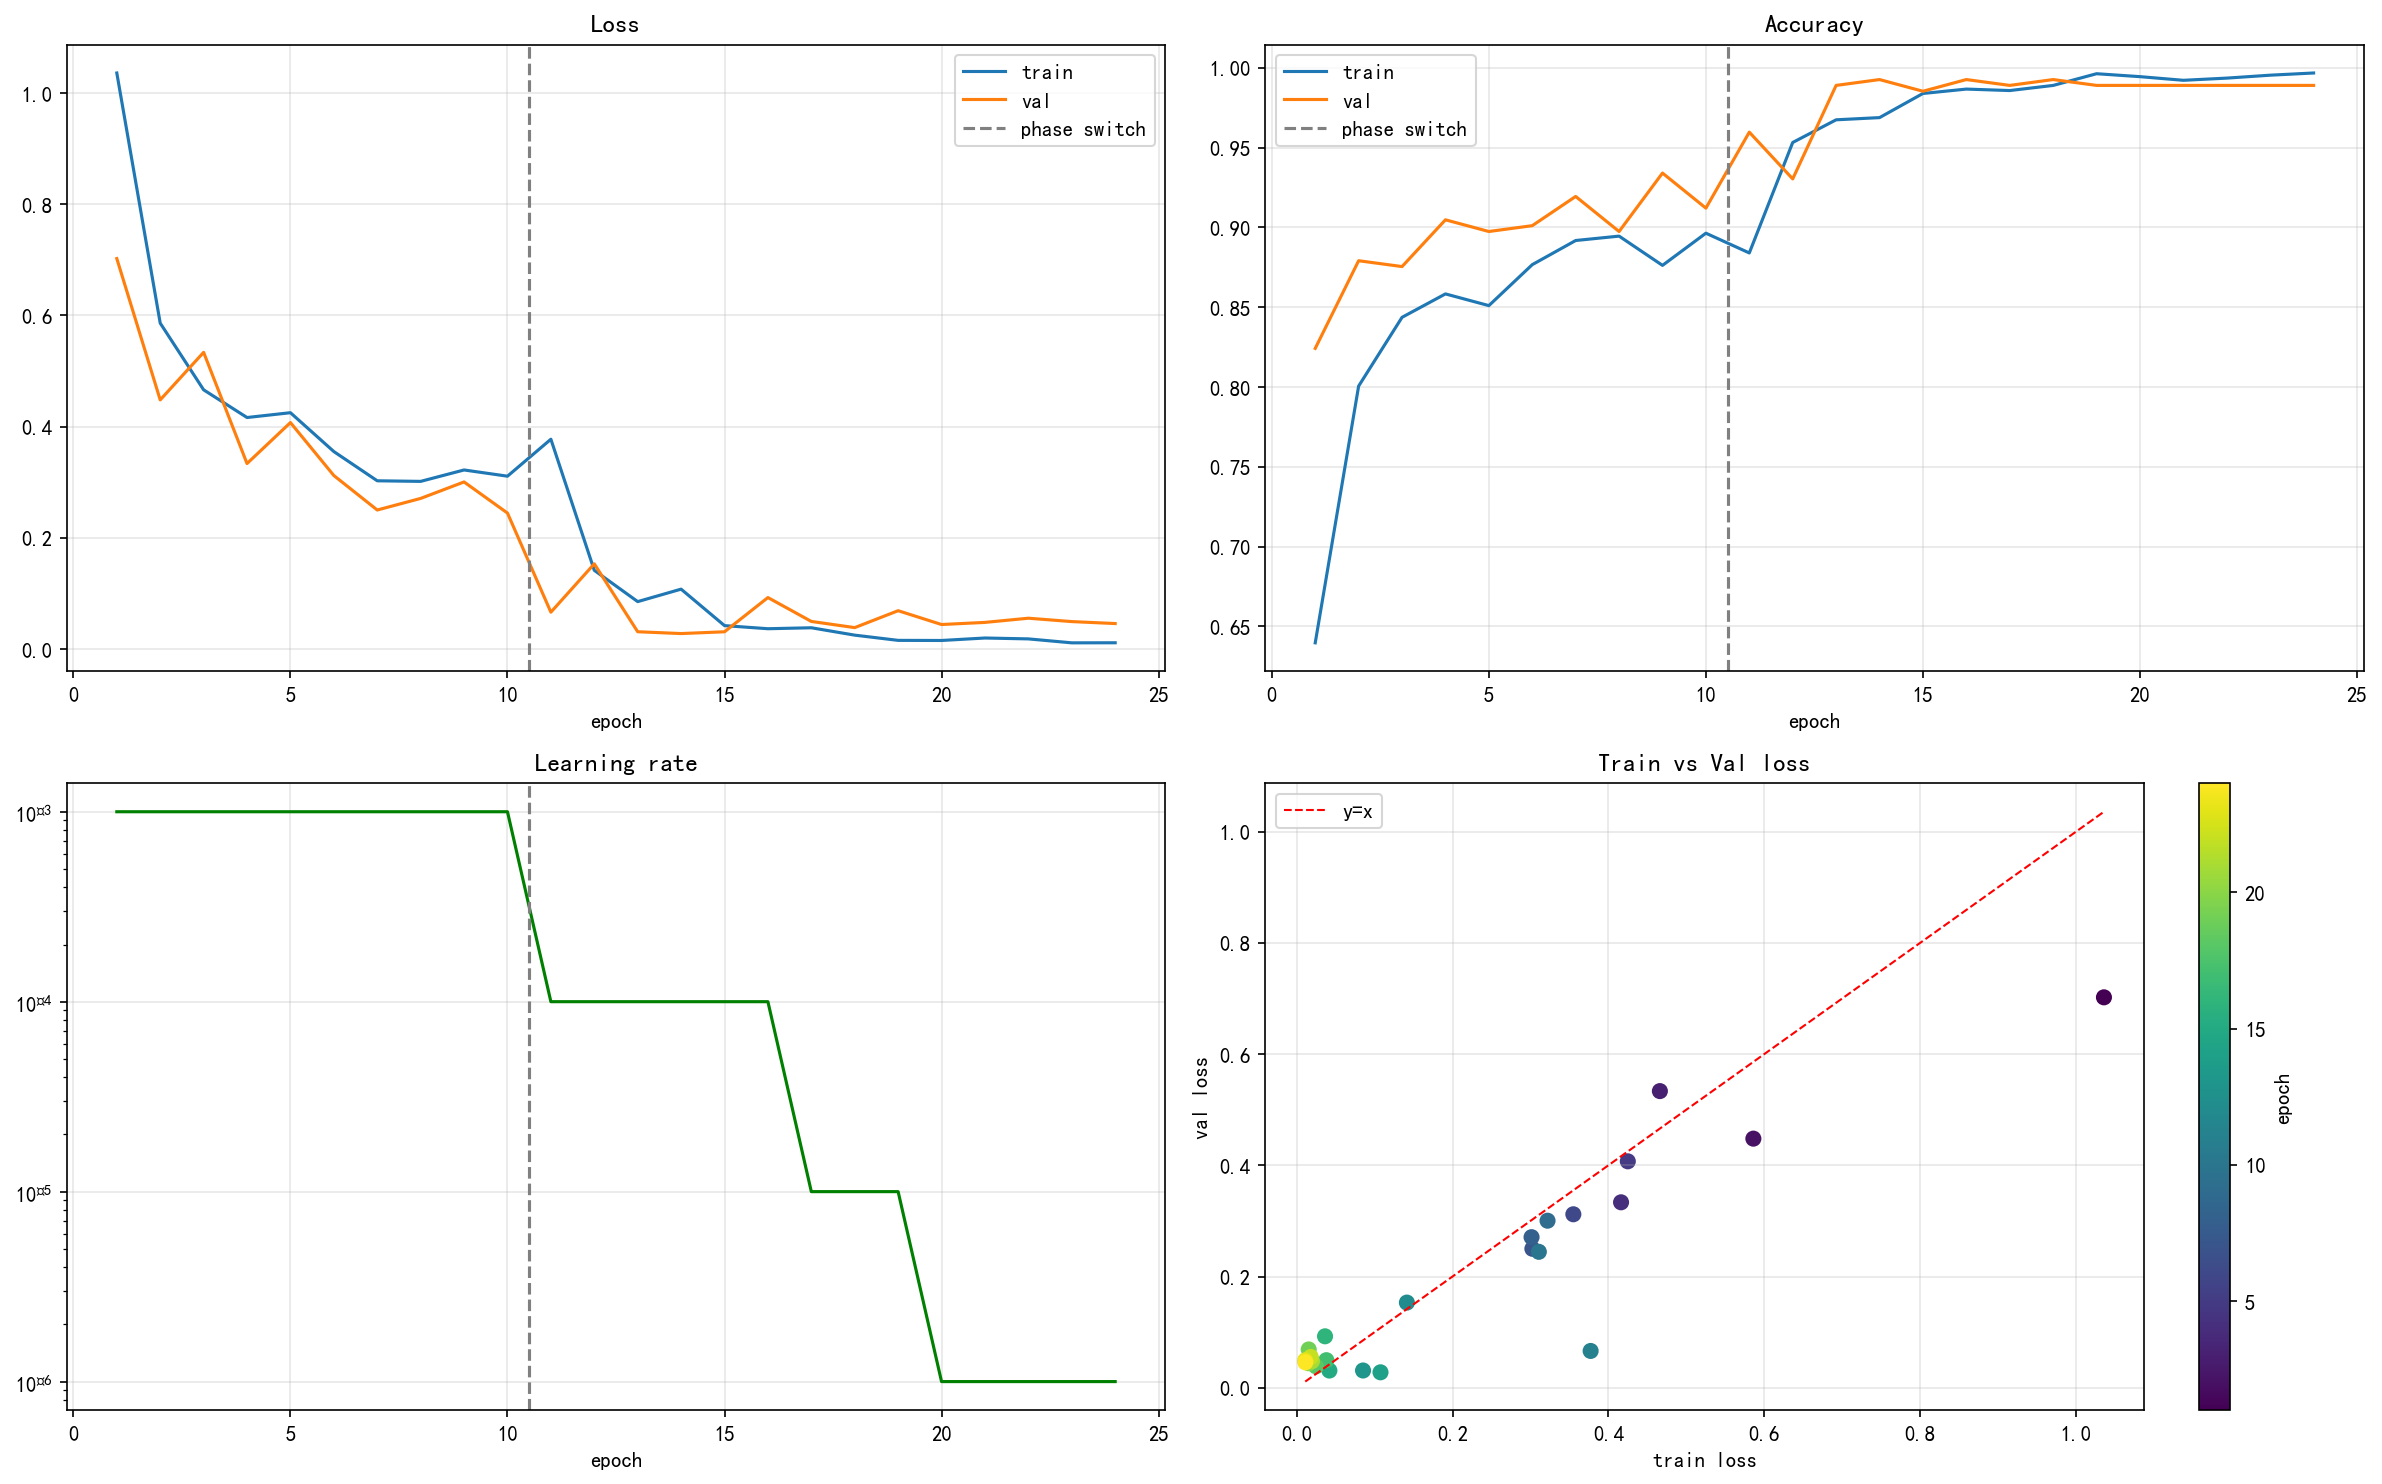

In [8]:
def plot_history(history, path):
    frame = pd.DataFrame(history)

    fig, axes = plt.subplots(2, 2, figsize=(16, 10))

    axes[0, 0].plot(frame["epoch"], frame["train_loss"], label="train")
    axes[0, 0].plot(frame["epoch"], frame["val_loss"], label="val")
    axes[0, 0].axvline(PHASE1_EPOCHS + 0.5, color="gray", linestyle="--", label="phase switch")
    axes[0, 0].set_title("Loss")
    axes[0, 0].set_xlabel("epoch")
    axes[0, 0].legend()
    axes[0, 0].grid(alpha=0.3)

    axes[0, 1].plot(frame["epoch"], frame["train_acc"], label="train")
    axes[0, 1].plot(frame["epoch"], frame["val_acc"], label="val")
    axes[0, 1].axvline(PHASE1_EPOCHS + 0.5, color="gray", linestyle="--", label="phase switch")
    axes[0, 1].set_title("Accuracy")
    axes[0, 1].set_xlabel("epoch")
    axes[0, 1].legend()
    axes[0, 1].grid(alpha=0.3)

    axes[1, 0].plot(frame["epoch"], frame["lr"], color="green")
    axes[1, 0].axvline(PHASE1_EPOCHS + 0.5, color="gray", linestyle="--")
    axes[1, 0].set_yscale("log")
    axes[1, 0].set_title("Learning rate")
    axes[1, 0].set_xlabel("epoch")
    axes[1, 0].grid(alpha=0.3)

    scatter = axes[1, 1].scatter(
        frame["train_loss"], frame["val_loss"], c=frame["epoch"], cmap="viridis", s=45
    )
    low = min(frame["train_loss"].min(), frame["val_loss"].min())
    high = max(frame["train_loss"].max(), frame["val_loss"].max())
    axes[1, 1].plot([low, high], [low, high], "r--", linewidth=1, label="y=x")
    axes[1, 1].set_title("Train vs Val loss")
    axes[1, 1].set_xlabel("train loss")
    axes[1, 1].set_ylabel("val loss")
    axes[1, 1].legend()
    axes[1, 1].grid(alpha=0.3)
    fig.colorbar(scatter, ax=axes[1, 1], label="epoch")

    plt.tight_layout()
    plt.savefig(path, dpi=150, bbox_inches="tight")
    plt.close(fig)


history_path = OUTPUT_ROOT / "training_curves.png"
if ("history" not in globals()) or (not history):
    history_csv = OUTPUT_ROOT / "training_history.csv"
    if not history_csv.exists():
        raise RuntimeError("没有可用的训练历史，请先运行训练 cell")
    history = pd.read_csv(history_csv).to_dict("records")
plot_history(history, history_path)
display(IPyImage(filename=str(history_path)))

## 7. 测试集最终评估

Test accuracy: 0.9743
Test loss: 0.0913
Macro precision: 0.9516
Macro recall: 0.9800
Macro F1: 0.9651
Macro AUC: 0.9988771369808389


,precision,recall,f1,support
Bacterial Rot,0.9091,1.0000,0.9524,10.0
Downey Mildew,0.9688,0.9688,0.9688,96.0
Healthy Leaves,1.0000,0.9762,0.9880,126.0
Powdery Mildew,0.9286,0.9750,0.9512,40.0


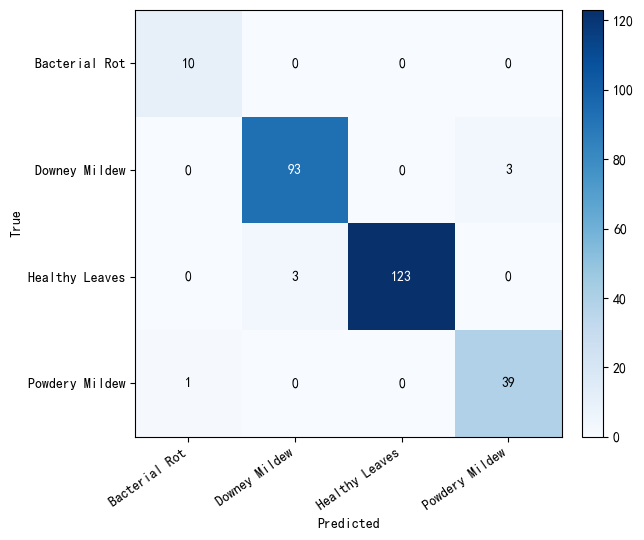

评估结果已保存:
  D:\WorkSpace2\plants-intelligent-system\train\runs\ngld_resnet50_cbam\metrics.json
  D:\WorkSpace2\plants-intelligent-system\train\runs\ngld_resnet50_cbam\classification_report.csv
  D:\WorkSpace2\plants-intelligent-system\train\runs\ngld_resnet50_cbam\confusion_matrix.png


In [9]:
checkpoint = torch.load(CHECKPOINT_PATH, map_location=DEVICE)
model = ResNet50CBAM(num_classes, pretrained=False).to(DEVICE)
model.load_state_dict(checkpoint["model_state_dict"])
model.eval()

test_loss, test_acc, y_true, y_pred, y_prob = evaluate(model, test_loader, criterion)
test_accuracy = float(accuracy_score(y_true, y_pred))

precision, recall, f1, _ = precision_recall_fscore_support(
    y_true, y_pred, labels=list(range(num_classes)), average="macro", zero_division=0
)
precision_w, recall_w, f1_w, _ = precision_recall_fscore_support(
    y_true, y_pred, labels=list(range(num_classes)), average="weighted", zero_division=0
)
try:
    auc = float(roc_auc_score(y_true, y_prob, multi_class="ovr", average="macro"))
except Exception as exc:
    print("AUC 计算失败:", exc)
    auc = None

report = classification_report(
    y_true, y_pred, labels=list(range(num_classes)),
    target_names=class_names, output_dict=True, zero_division=0,
)
cm = confusion_matrix(y_true, y_pred, labels=list(range(num_classes)))

print(f"Test accuracy: {test_accuracy:.4f}")
print(f"Test loss: {test_loss:.4f}")
print(f"Macro precision: {precision:.4f}")
print(f"Macro recall: {recall:.4f}")
print(f"Macro F1: {f1:.4f}")
print(f"Macro AUC: {auc}")

per_class = pd.DataFrame({
    name: {
        "precision": report[name]["precision"],
        "recall": report[name]["recall"],
        "f1": report[name]["f1-score"],
        "support": int(report[name]["support"]),
    }
    for name in class_names
}).T
display(per_class.round(4))

fig, ax = plt.subplots(figsize=(6.5, 5.5))
im = ax.imshow(cm, cmap="Blues")
fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
ax.set_xticks(range(num_classes))
ax.set_yticks(range(num_classes))
ax.set_xticklabels(class_names, rotation=35, ha="right")
ax.set_yticklabels(class_names)
ax.set_xlabel("Predicted")
ax.set_ylabel("True")
threshold = cm.max() / 2.0 if cm.max() > 0 else 0
for i in range(num_classes):
    for j in range(num_classes):
        ax.text(j, i, str(cm[i, j]), ha="center", va="center",
                color="white" if cm[i, j] > threshold else "black")
plt.tight_layout()
confusion_path = OUTPUT_ROOT / "confusion_matrix.png"
plt.savefig(confusion_path, dpi=150, bbox_inches="tight")
plt.show()

metrics = {
    "test_accuracy": test_accuracy,
    "test_loss": float(test_loss),
    "precision_macro": float(precision),
    "recall_macro": float(recall),
    "f1_macro": float(f1),
    "precision_weighted": float(precision_w),
    "recall_weighted": float(recall_w),
    "f1_weighted": float(f1_w),
    "auc_macro": auc,
    "per_class": per_class.to_dict(orient="index"),
    "confusion_matrix": cm.tolist(),
    "class_names": class_names,
    "best_epoch": checkpoint["epoch"],
    "best_phase": checkpoint["phase"],
    "best_val_loss": checkpoint["val_loss"],
    "best_val_acc": checkpoint["val_acc"],
}
with open(OUTPUT_ROOT / "metrics.json", "w", encoding="utf-8") as fh:
    json.dump(metrics, fh, ensure_ascii=False, indent=2, default=float)
per_class.to_csv(OUTPUT_ROOT / "classification_report.csv", encoding="utf-8-sig")

print("评估结果已保存:")
print(f"  {OUTPUT_ROOT / 'metrics.json'}")
print(f"  {OUTPUT_ROOT / 'classification_report.csv'}")
print(f"  {confusion_path}")